# 06 · Simulación de producción por lotes y resultado de negocio

La simulación se ejecutó con los flujos de Kestra (`simulacion` → `produccion_lotes`, `monitoreo` y
`reentrenamiento`). Este notebook no la repite: lee lo que dejó en Snowflake (esquema `PSET2_DB.PRODUCCION`) y en
MLflow y responde cuatro preguntas.

1. Cómo se construyeron los 10 lotes semanales y qué se alteró a propósito (§1 y §2).
2. Qué respondió el servicio en cada lote (§3).
3. Cuánto ahorró el modelo frente a la línea base de negocio, lote por lote, y qué efecto tuvieron los
   reentrenamientos (§4 y §5, sección 9 del enunciado), y qué tan independiente es esa medición (§6).
4. Cómo se rastrea una predicción hasta el modelo, los datos con que se entrenó y las tablas Gold (§7).

El monitoreo, las alertas, la deriva y el análisis por subgrupo están en `07_analisis_monitoreo.ipynb`.

In [1]:
import json
import os
import sys
import warnings

sys.path.insert(0, '..')
os.environ.setdefault('MLFLOW_DISABLE_AGENT_HINT', '1')
os.environ.setdefault('MLFLOW_ENABLE_ARTIFACTS_PROGRESS_BAR', 'false')
# MLflow 3.18 exige este permiso para deserializar los modelos del registro (formato skops).
os.environ['MLFLOW_ALLOW_MODEL_CODE_EXECUTION'] = 'true'
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
from dotenv import load_dotenv
from mlflow.tracking import MlflowClient

from src.datos import RUTA_META, consultar
from src.lotes import COLUMNAS_X, DERIVA_DEMANDA, DERIVA_FUENTE, calendario_lotes
from src.negocio import CO, CU, ReglaRespaldo, resultado_negocio
from src.reentrenar import MODELO_REGISTRADO, tipos_firma

load_dotenv('../.env')
cliente = MlflowClient()
ESQUEMA = 'PSET2_DB.PRODUCCION'

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)
pd.set_option('display.float_format', '{:,.4f}'.format)

# Colores: una serie principal, la línea base en gris y los reentrenamientos (verde aprobado, gris rechazado).
SERIE, LINEA_BASE, APROBADO, RECHAZADO, CRITICO = '#2a78d6', '#898781', '#0ca30c', '#898781', '#d03b3b'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e1e0d9', 'axes.axisbelow': True})

C:\Users\lroja\MSDS\Data Science\Pset3\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Calendario de los lotes

Un lote es una **semana de ventas (lunes a domingo) de las 2.000 series** de la muestra del PSet 3. Las decisiones del
calendario (`src/lotes.py`):

- **Día de la predicción:** el lunes anterior a la semana, cuando se decide el pedido. Ese día se conocen las ventas
  hasta el domingo previo. El día más tardío del lote necesita datos hasta t−16, que ya existen: ninguna feature usa
  información posterior al día de la predicción.
- **Llegada del target:** el lunes siguiente al cierre de la semana, que coincide con la predicción del lote k+2.
  El desempeño de un lote se conoce **dos pasos después** de predecirlo, nunca junto con la predicción.
- **Primer lote:** semana del 05/06/2017, predicha el 29/05 con datos hasta el 28/05, que es el corte de entrenamiento
  del champion inicial (versión 3). Hasta el 13/08/2017 caben 10 lotes completos; el 14 y el 15 de agosto quedan fuera.

Los datos sí están ordenados en el tiempo: los lotes son las semanas siguientes al entrenamiento, en orden, sin
mezclar fechas.

In [2]:
calendario = calendario_lotes()
lotes_resumen = consultar(f'''
    SELECT LOTE, MIN(DATE) AS DESDE, MAX(DATE) AS HASTA, ANY_VALUE(FECHA_PREDICCION) AS FECHA_PREDICCION,
           ANY_VALUE(FECHA_LLEGADA_TARGET) AS LLEGA_TARGET, ANY_VALUE(DERIVA) AS DERIVA,
           COUNT(*) AS FILAS, COUNT(DEFECTO) AS FILAS_DEFECTUOSAS,
           COUNT(DISTINCT STORE_NBR || '-' || ITEM_NBR) AS SERIES
    FROM {ESQUEMA}.LOTES GROUP BY LOTE ORDER BY LOTE''', 'PSET4_NB06')
lotes_resumen

,LOTE,DESDE,HASTA,FECHA_PREDICCION,LLEGA_TARGET,DERIVA,FILAS,FILAS_DEFECTUOSAS,SERIES
0,1,2017-06-05,2017-06-11,2017-05-29,2017-06-12,ninguna,13983,0,1998
1,2,2017-06-12,2017-06-18,2017-06-05,2017-06-19,ninguna,13998,0,2000
2,3,2017-06-19,2017-06-25,2017-06-12,2017-06-26,fuente_transacciones,14003,3,2000
3,4,2017-06-26,2017-07-02,2017-06-19,2017-07-03,ninguna,14000,0,2000
4,5,2017-07-03,2017-07-09,2017-06-26,2017-07-10,demanda,14000,0,2000
5,6,2017-07-10,2017-07-16,2017-07-03,2017-07-17,demanda,14000,0,2000
6,7,2017-07-17,2017-07-23,2017-07-10,2017-07-24,demanda,14000,0,2000
7,8,2017-07-24,2017-07-30,2017-07-17,2017-07-31,demanda,14000,0,2000
8,9,2017-07-31,2017-08-06,2017-07-24,2017-08-07,demanda,14000,0,2000
9,10,2017-08-07,2017-08-13,2017-07-31,2017-08-14,demanda,14000,0,2000


Los lotes 1 y 2 tienen menos de 14.000 filas (13.983 y 13.998) porque algunas series de la muestra todavía no
existían en esos días (productos que se empezaron a vender después). El lote 3 tiene 3 filas de más: las filas
defectuosas de §2.

## 2. Las dos alteraciones inducidas

Los lotes 1, 2 y 4 no se tocan: son el **control de falsas alarmas**. Se alteran dos cosas distintas, para que el
monitoreo tenga que separar los dos tipos de deriva:

| Lote | Alteración | Qué simula | Qué debería ver el monitoreo |
|---|---|---|---|
| 3 | `transacciones_lag_16` llega como log1p(transacciones × 0,5); la venta real no cambia. Más 3 filas defectuosas. | El sistema de cajas empieza a contar la mitad de las transacciones. | PSI alto en una feature, desempeño normal: **deriva de datos sin impacto**. La API rechaza las 3 filas con 422. |
| 5 a 10 | La venta real de todas las series se multiplica por 1,5 desde el 03/07/2017. Las features se recalculan con esa venta. | Cierre de un competidor: la demanda sube y se queda alta. | Primeros lotes: entradas casi normales (miran t−16) y pérdida alta: **deriva conceptual**. Después, los rezagos recogen el aumento y el PSI sube: **deriva de datos**, con o sin impacto según la pérdida. |

Las dos alteraciones se ven directamente en los datos de los lotes:

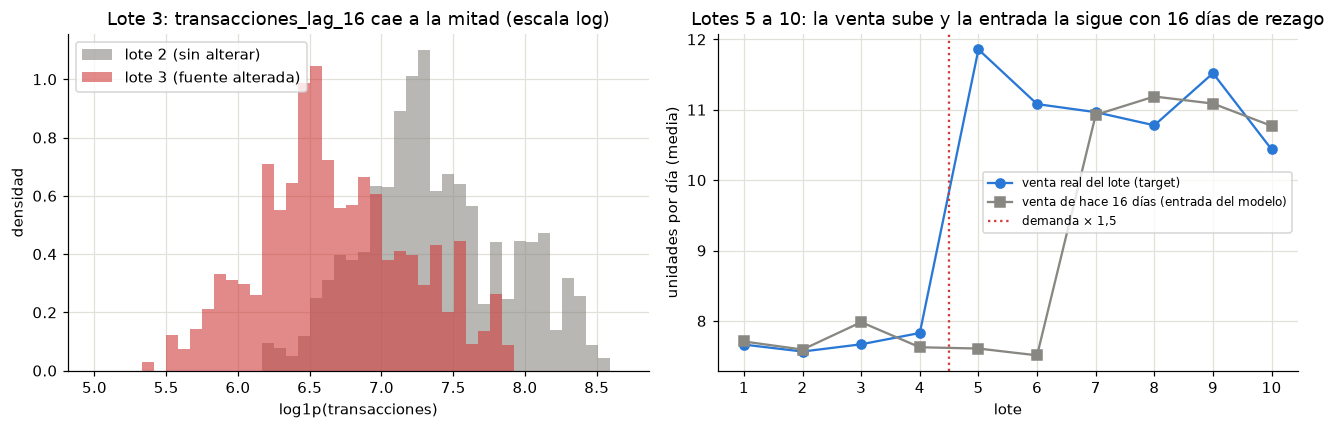

LOTE,1,2,3,4,5,6,7,8,9,10
venta_real,7.6600,7.5700,7.6700,7.8300,11.8600,11.0800,10.9700,10.7800,11.5200,10.4400
venta_hace_16_dias,7.7100,7.5900,7.9800,7.6300,7.6100,7.5100,10.9300,11.1900,11.0900,10.7700


In [3]:
filas = consultar(f'''
    SELECT l.LOTE, l.DEFECTO, l.TRANSACCIONES_LAG_16, l.VENTA_LAG_16, t.UNIT_SALES_TARGET
    FROM {ESQUEMA}.LOTES l
    LEFT JOIN {ESQUEMA}.LOTES_TARGET t
           ON t.STORE_NBR = l.STORE_NBR AND t.ITEM_NBR = l.ITEM_NBR AND t.DATE = l.DATE
    WHERE l.DEFECTO IS NULL''', 'PSET4_NB06')

figura, (eje1, eje2) = plt.subplots(1, 2, figsize=(12, 4))
cortes = np.linspace(5, filas['TRANSACCIONES_LAG_16'].max(), 45)
for lote, color, etiqueta in [(2, LINEA_BASE, 'lote 2 (sin alterar)'), (3, CRITICO, 'lote 3 (fuente alterada)')]:
    eje1.hist(filas.loc[filas['LOTE'] == lote, 'TRANSACCIONES_LAG_16'], bins=cortes, alpha=0.6, color=color,
              label=etiqueta, density=True)
eje1.set(title='Lote 3: transacciones_lag_16 cae a la mitad (escala log)', xlabel='log1p(transacciones)',
         ylabel='densidad')
eje1.legend()

por_lote = filas.groupby('LOTE').agg(venta_real=('UNIT_SALES_TARGET', 'mean'),
                                     venta_hace_16_dias=('VENTA_LAG_16', lambda v: np.expm1(v).mean()))
eje2.plot(por_lote.index, por_lote['venta_real'], marker='o', color=SERIE, label='venta real del lote (target)')
eje2.plot(por_lote.index, por_lote['venta_hace_16_dias'], marker='s', color=LINEA_BASE,
          label='venta de hace 16 días (entrada del modelo)')
eje2.axvline(DERIVA_DEMANDA['desde_lote'] - 0.5, color=CRITICO, linestyle=':', label='demanda × 1,5')
eje2.set(title='Lotes 5 a 10: la venta sube y la entrada la sigue con 16 días de rezago', xlabel='lote',
         ylabel='unidades por día (media)', xticks=range(1, 11))
eje2.legend(fontsize=8)
figura.tight_layout()
plt.show()
por_lote.round(2).T

- **Lote 3.** La distribución de `transacciones_lag_16` se desplaza en bloque hacia la izquierda: es la misma tienda
  con la mitad de transacciones. Nada más cambia.
- **Lotes 5 a 10.** La venta real salta un 50 % en el lote 5. La venta de hace 16 días, que es la entrada del
  modelo, sigue en el nivel anterior en los lotes 5 y 6 y alcanza el nuevo nivel en el lote 7. Durante esas dos
  semanas el modelo pide para una demanda que ya no existe, sin que nada en sus entradas lo delate: es la ventana de
  la deriva conceptual. El análisis del monitoreo (notebook 07) muestra cómo el PSI y la pérdida separan las dos
  fases.

## 3. Lo que respondió el servicio

Kestra (`produccion_lotes.yml`) mandó cada lote a la API en bloques de 2.000 filas (`POST /predecir/lote`). La API
guardó cada predicción en su registro con la versión del modelo y el `run_id`, y otra tarea la cargó en
`PRODUCCION.PREDICCIONES`. Si un bloque vuelve con 422, el cliente quita las filas señaladas y reenvía el resto: una
fila mal formada no detiene el pedido de la semana.

In [4]:
servido = consultar(f'''
    SELECT LOTE, COUNT(*) AS PREDICCIONES, COUNT(DISTINCT EJECUCION) AS EJECUCIONES,
           LISTAGG(DISTINCT VERSION_MODELO, ',') AS VERSION_MODELO, SUM(IFF(USO_RESPALDO, 1, 0)) AS CON_RESPALDO,
           AVG(PEDIDO) AS PEDIDO_MEDIO, AVG(IFF(DECISION = 'reponer', 1, 0)) AS TASA_REPONER
    FROM {ESQUEMA}.PREDICCIONES GROUP BY LOTE ORDER BY LOTE''', 'PSET4_NB06')
servido = servido.merge(lotes_resumen[['LOTE', 'FILAS', 'FILAS_DEFECTUOSAS']], on='LOTE')
servido['SIN_PREDICCION'] = servido['FILAS'] - servido['PREDICCIONES']
assert (servido['SIN_PREDICCION'] == servido['FILAS_DEFECTUOSAS']).all(), 'Solo las filas defectuosas quedan sin pedido'
servido

,LOTE,PREDICCIONES,EJECUCIONES,VERSION_MODELO,CON_RESPALDO,PEDIDO_MEDIO,TASA_REPONER,FILAS,FILAS_DEFECTUOSAS,SIN_PREDICCION
0,1,13983,1,3,0,9.8710,0.900737,13983,0,0
1,2,13998,1,3,0,9.7743,0.902486,13998,0,0
2,3,14000,1,3,0,9.6175,0.903857,14003,3,3
3,4,14000,1,3,0,10.2861,0.898500,14000,0,0
4,5,14000,1,3,0,10.2073,0.896643,14000,0,0
5,6,14000,1,3,0,9.6426,0.894929,14000,0,0
6,7,14000,1,3,0,9.9845,0.901286,14000,0,0
7,8,14000,1,3,0,10.5100,0.904643,14000,0,0
8,9,14000,1,3,0,12.0559,0.905000,14000,0,0
9,10,14000,1,3,0,12.0263,0.902000,14000,0,0


- **Todas las filas válidas recibieron pedido** y las únicas sin predicción son las 3 filas defectuosas del lote 3,
  que la API rechazó con 422.
- **Los 10 lotes los sirvió la versión 3**, sin uso de la regla de respaldo. El único reentrenamiento aprobado de la
  simulación (paso 10) ocurrió después de predecir el lote 10, así que ninguna versión nueva llegó a servir un lote
  (§5).
- **El pedido medio sube en los lotes 9 y 10** sin reentrenar: las entradas (venta de hace 16 días) ya recogen el
  aumento de demanda y el modelo pide más. La tasa de decisión `reponer` (pedido ≥ 0,5 unidades) se mantiene cerca
  del 90 %.

## 4. Resultado de negocio lote por lote (sección 9)

**Métrica de negocio:** el costo *newsvendor* del PSet 3, `costo = Co · sobrantes + Cu · faltantes` con
**Co:Cu = 1:3** (que falte una unidad cuesta tres veces más que que sobre). Se calcula con los pedidos que el servicio
**realmente entregó** y la venta real de cada lote.

**Línea base:** la regla de negocio, que es también la regla de respaldo de la API (`api/respaldo.json`): media de
los últimos 28 días (desde t−16) más un stock de seguridad aditivo por familia.

**No hacer nada no aplica.** En perecederos, no pedir significa no tener producto: el costo sería el de faltante de
toda la demanda (Cu × venta total), un escenario que ninguna tienda considera. El proceso actual es la regla, y contra
ella se mide el modelo.

El costo se recalcula fila por fila y se compara con `PRODUCCION.DESEMPENO`, que el flujo `produccion_lotes`
calculó al llegar el target de cada lote.

In [5]:
datos = consultar(f'''
    SELECT l.*, p.PEDIDO, p.DECISION, p.VERSION_MODELO, t.UNIT_SALES_TARGET
    FROM {ESQUEMA}.PREDICCIONES p
    JOIN {ESQUEMA}.LOTES l ON l.STORE_NBR = p.STORE_NBR AND l.ITEM_NBR = p.ITEM_NBR AND l.DATE = p.DATE
                          AND l.DEFECTO IS NULL
    JOIN {ESQUEMA}.LOTES_TARGET t ON t.STORE_NBR = p.STORE_NBR AND t.ITEM_NBR = p.ITEM_NBR AND t.DATE = p.DATE''',
                  'PSET4_NB06')
datos = datos.rename(columns={c.upper(): c for c in COLUMNAS_X})
X = tipos_firma(datos[COLUMNAS_X])
datos['PEDIDO_REGLA'] = ReglaRespaldo.cargar('../api/respaldo.json').predict(X)


def negocio(grupo, pedido='PEDIDO'):
    r = resultado_negocio(grupo['UNIT_SALES_TARGET'], grupo[pedido])
    return pd.Series({'costo': r['costo'], 'merma': r['merma'], 'cobertura': r['cobertura']})


modelo = datos.groupby('LOTE').apply(negocio, include_groups=False)
regla = datos.groupby('LOTE').apply(negocio, pedido='PEDIDO_REGLA', include_groups=False)
resultado = pd.DataFrame({
    'costo_modelo': modelo['costo'], 'costo_regla': regla['costo'],
    'ahorro_vs_regla_pct': 100 * (1 - modelo['costo'] / regla['costo']),
    'merma_modelo': modelo['merma'], 'merma_regla': regla['merma'],
    'cobertura_modelo': modelo['cobertura'], 'cobertura_regla': regla['cobertura']})

desempeno = consultar(f'SELECT LOTE, COSTO, COSTO_REGLA, AHORRO_VS_REGLA_PCT FROM {ESQUEMA}.DESEMPENO ORDER BY LOTE',
                      'PSET4_NB06').set_index('LOTE')
assert np.allclose(resultado['costo_modelo'], desempeno['COSTO']) and \
       np.allclose(resultado['costo_regla'], desempeno['COSTO_REGLA']), 'No coincide con PRODUCCION.DESEMPENO'
print('El recálculo coincide con PRODUCCION.DESEMPENO en los 10 lotes.')

total = resultado[['costo_modelo', 'costo_regla']].sum()
print(f'Los 10 lotes: costo del modelo {total["costo_modelo"]:,.0f}, de la regla {total["costo_regla"]:,.0f} '
      f'→ ahorro {100 * (1 - total["costo_modelo"] / total["costo_regla"]):.1f} %')
resultado.round({'costo_modelo': 0, 'costo_regla': 0, 'ahorro_vs_regla_pct': 1, 'merma_modelo': 3,
                 'merma_regla': 3, 'cobertura_modelo': 3, 'cobertura_regla': 3})

El recálculo coincide con PRODUCCION.DESEMPENO en los 10 lotes.
Los 10 lotes: costo del modelo 1,264,359, de la regla 1,626,258 → ahorro 22.3 %


,costo_modelo,costo_regla,ahorro_vs_regla_pct,merma_modelo,merma_regla,cobertura_modelo,cobertura_regla
LOTE,,,,,,,
1,"90,368.0000","119,441.0000",24.3000,0.3310,0.3490,0.8610,0.7650
2,"89,287.0000","116,382.0000",23.3000,0.3330,0.3480,0.8620,0.7710
3,"86,013.0000","116,206.0000",26.0000,0.3120,0.3390,0.8630,0.7710
4,"87,247.0000","123,947.0000",29.6000,0.3310,0.3400,0.8790,0.7520
5,"178,413.0000","234,252.0000",23.8000,0.1910,0.2230,0.6970,0.5860
6,"163,352.0000","208,840.0000",21.8000,0.1910,0.2390,0.7040,0.6160
7,"155,424.0000","196,331.0000",20.8000,0.2040,0.2370,0.7250,0.6400
8,"146,269.0000","179,927.0000",18.7000,0.2290,0.2600,0.7510,0.6820
9,"141,605.0000","182,245.0000",22.3000,0.2430,0.2430,0.7920,0.6980


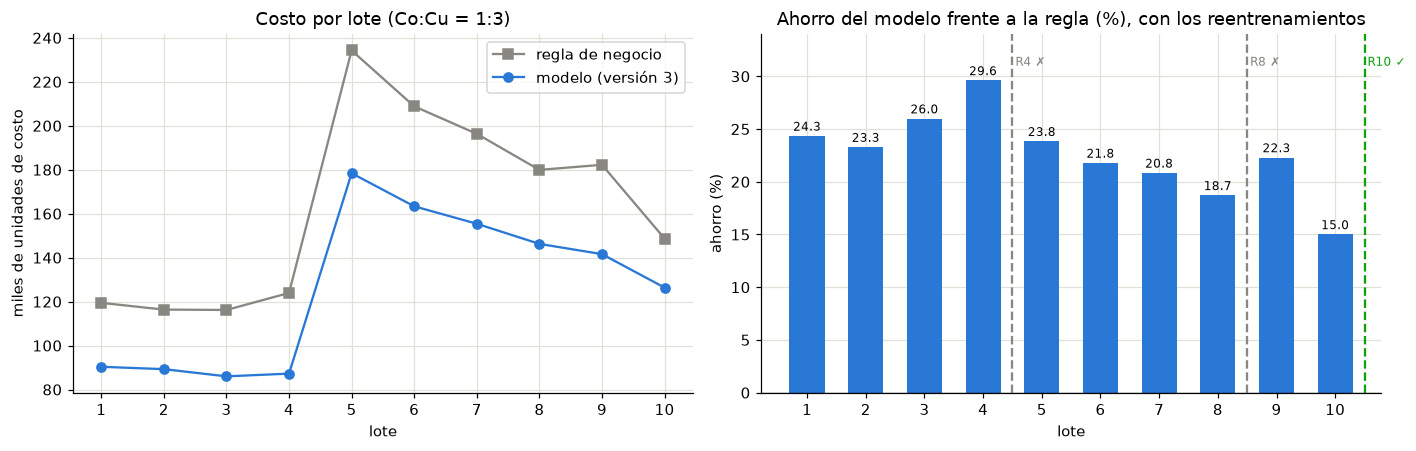

In [6]:
reentrenamientos = consultar(f'SELECT * FROM {ESQUEMA}.REENTRENAMIENTOS ORDER BY PASO', 'PSET4_NB06')
simulacion = reentrenamientos[reentrenamientos['MOTIVO'] != 'demostracion']

figura, (eje1, eje2) = plt.subplots(1, 2, figsize=(13, 4.2))
eje1.plot(resultado.index, resultado['costo_regla'] / 1000, marker='s', color=LINEA_BASE, label='regla de negocio')
eje1.plot(resultado.index, resultado['costo_modelo'] / 1000, marker='o', color=SERIE, label='modelo (versión 3)')
eje1.set(title='Costo por lote (Co:Cu = 1:3)', xlabel='lote', ylabel='miles de unidades de costo', xticks=range(1, 11))
eje1.legend()

eje2.bar(resultado.index, resultado['ahorro_vs_regla_pct'], color=SERIE, width=0.6)
for lote, valor in resultado['ahorro_vs_regla_pct'].items():
    eje2.text(lote, valor + 0.5, f'{valor:.1f}', ha='center', fontsize=8)
eje2.axhline(0, color='black', linewidth=0.8)
for _, r in simulacion.iterrows():
    color = APROBADO if r['DECISION'] == 'aprobado' else RECHAZADO
    marca = '✓' if r['DECISION'] == 'aprobado' else '✗'
    eje2.axvline(r['PASO'] + 0.5, color=color, linestyle='--')
    eje2.text(r['PASO'] + 0.55, 31, f"R{r['PASO']} {marca}", color=color, fontsize=8)
eje2.set(title='Ahorro del modelo frente a la regla (%), con los reentrenamientos', xlabel='lote',
         ylabel='ahorro (%)', xticks=range(1, 11), ylim=(0, 34))
figura.tight_layout()
plt.show()

**Lectura.**

- **El modelo le ganó a la regla en los 10 lotes**, también durante las dos derivas. Ningún lote quedó por debajo de
  la línea base, así que el criterio de retirada por negocio (ahorro < 0) nunca se activó.
- **El modelo mejora las dos caras del error a la vez**: cubre más demanda que la regla (cobertura 86–88 % contra
  75–77 % en los lotes normales) y desperdicia una fracción igual o menor de lo que pide (merma 31–33 % contra
  34–35 %). No es un intercambio de faltantes por sobrantes: pide mejor repartido entre series y días.
- **Durante el aumento de demanda los dos costos se duplican** (lote 5) y la cobertura de los dos cae (70 % y 59 %),
  porque los dos pedían para la demanda anterior. El modelo se recupera antes: su ahorro baja de 29,6 % (lote 4) a 23,8 % (lote 5), pero sigue positivo.
- **El lote 10 tiene el ahorro más bajo (15,0 %).** No es porque el modelo empeore (su costo es el más bajo desde el
  lote 4), sino porque la regla mejora más: su media de 28 días ya cubre casi solo semanas con la demanda nueva y se
  ajustó al nuevo nivel.
- **Las líneas de reentrenamiento no cambian la serie**: los pasos 4 y 8 se rechazaron y el paso 10 se aprobó después
  del último lote. El efecto de cada reentrenamiento se mide en §5.

## 5. Efecto de los reentrenamientos

Los cuatro reentrenamientos registrados (`PRODUCCION.REENTRENAMIENTOS`): tres de la simulación y uno manual (paso 12)
hecho en la demostración del video, después del rollback a la versión 3 (por eso la v8 se compara con la v3). La
versión 4 del registro es una corrida de prueba del flujo, anterior a la simulación, sin decisión. Cómo se tomó cada
decisión (con el formulario de la pausa o aplicada a mano) se detalla en el notebook 07, §8.

In [7]:
columnas = ['PASO', 'MOTIVO', 'LOTES_ENTRENAMIENTO', 'LOTE_EVALUACION', 'VERSION_CHAMPION', 'VERSION_CHALLENGER',
            'AHORRO_VS_REGLA_PCT_CHAMPION', 'AHORRO_VS_REGLA_PCT_CHALLENGER', 'DIFERENCIA_AHORRO_PP',
            'UMBRAL_PROMOCION_PP', 'RECOMENDACION', 'DECISION', 'MOTIVO_DECISION']
reentrenamientos[columnas]

,PASO,MOTIVO,LOTES_ENTRENAMIENTO,LOTE_EVALUACION,VERSION_CHAMPION,VERSION_CHALLENGER,AHORRO_VS_REGLA_PCT_CHAMPION,AHORRO_VS_REGLA_PCT_CHALLENGER,DIFERENCIA_AHORRO_PP,UMBRAL_PROMOCION_PP,RECOMENDACION,DECISION,MOTIVO_DECISION
0,4,calendario: cada 4 lotes (paso 4),[1],2,3,5,23.2813,25.5606,2.2792,2.7817,mantener champion,rechazado,reanudado sin formulario: se mantiene el champion
1,8,desempeño: pérdida relativa > 0.2415 en los lo...,"[1, 2, 3, 4, 5]",6,3,6,21.7813,23.8199,2.0386,2.7817,mantener champion,rechazado,"Mejora de +2.04 pp, menor que 1σ de la CV (2.7..."
2,10,desempeño: pérdida relativa > 0.2415 en los lo...,"[1, 2, 3, 4, 5, 6, 7]",8,3,7,18.7069,22.8326,4.1257,2.7817,promover,aprobado,Correccion manual: el Restart reanudo la pausa...
3,12,demostracion,"[1, 2, 3, 4, 5, 6, 7, 8, 9]",10,3,8,15.0002,18.8281,3.8279,2.7817,promover,aprobado,"Mejora de +3.83 pp, mayor que 1σ de la CV (2.7..."


En la simulación ningún challenger llegó a servir un lote, así que su efecto no se ve en §4. Para medirlo se hace
un **contrafactual**: cada challenger predice los lotes que vinieron **después** de su ventana de entrenamiento (datos
que no vio) y se compara su ahorro con el de la versión 3, que fue la que sirvió. Responde si rechazar o aprobar fue
la decisión correcta.

| Versión | Paso | Entrenó con lotes | Lotes que no vio |
|---|---|---|---|
| 5 | 4 (rechazado) | 1 | 2 a 10 |
| 6 | 8 (rechazado) | 1 a 5 | 6 a 10 |
| 7 | 10 (aprobado) | 1 a 7 | 8 a 10 |
| 8 | 12 (demostración, aprobado) | 1 a 9 | 10 |

Primero se comprueba que la versión 3, cargada del registro, reproduce los pedidos que el servicio entregó.

In [8]:
modelos = {v: mlflow.sklearn.load_model(f'models:/{MODELO_REGISTRADO}/{v}') for v in ['3', '5', '6', '7', '8']}
pedidos = {v: np.clip(m.predict(X), 0, None) for v, m in modelos.items()}
# El registro de la API guarda el pedido con 3 decimales: la diferencia es solo de redondeo.
print('Máxima diferencia entre la versión 3 y lo servido:', f"{np.abs(pedidos['3'] - datos['PEDIDO']).max():.4f} unidades")

ultimo_visto = {'5': 1, '6': 5, '7': 7, '8': 9}
filas_cf = []
for version, visto in ultimo_visto.items():
    for lote in range(visto + 1, 11):
        en_lote = (datos['LOTE'] == lote).to_numpy()
        y = datos.loc[en_lote, 'UNIT_SALES_TARGET']
        costo_regla = resultado.loc[lote, 'costo_regla']
        filas_cf.append({'version': f'v{version}', 'lote': lote,
                         'ahorro_v3': 100 * (1 - resultado_negocio(y, pedidos['3'][en_lote])['costo'] / costo_regla),
                         'ahorro_challenger': 100 * (1 - resultado_negocio(y, pedidos[version][en_lote])['costo']
                                                     / costo_regla)})
contrafactual = pd.DataFrame(filas_cf)
contrafactual['diferencia_pp'] = contrafactual['ahorro_challenger'] - contrafactual['ahorro_v3']
contrafactual.pivot(index='lote', columns='version', values='diferencia_pp').round(2)

Máxima diferencia entre la versión 3 y lo servido: 0.0005 unidades


version,v5,v6,v7,v8
lote,,,,
2,2.2800,NaN,NaN,NaN
3,1.1200,NaN,NaN,NaN
4,0.5400,NaN,NaN,NaN
5,-0.0500,NaN,NaN,NaN
6,0.5800,2.0400,NaN,NaN
7,0.2600,0.6000,NaN,NaN
8,0.5300,1.8100,4.1300,NaN
9,0.8600,3.5200,5.1600,NaN
10,0.6700,2.3300,3.2300,3.8300


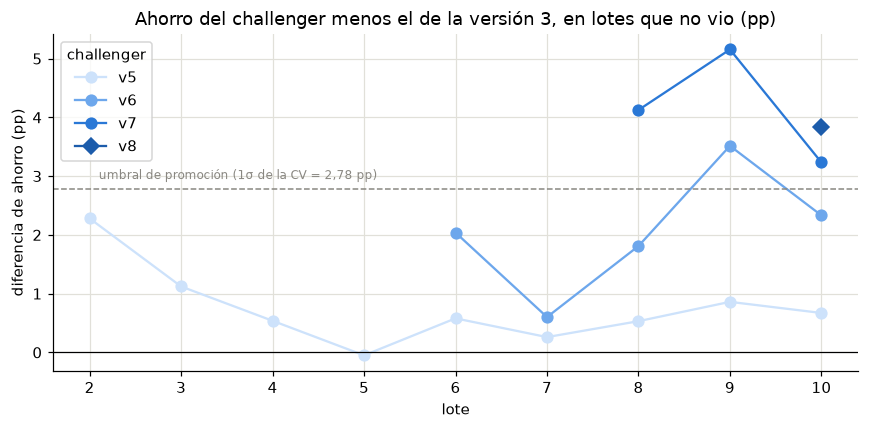

,mean,min,max,count
version,,,,
v5,0.7500,-0.0500,2.2800,9
v6,2.0600,0.6000,3.5200,5
v7,4.1700,3.2300,5.1600,3
v8,3.8300,3.8300,3.8300,1


In [9]:
figura, eje = plt.subplots(figsize=(8, 4))
for version, color, marca in [('v5', '#cde2fb', 'o'), ('v6', '#6da7ec', 'o'), ('v7', SERIE, 'o'), ('v8', '#1c5cab', 'D')]:
    parte = contrafactual[contrafactual['version'] == version]
    eje.plot(parte['lote'], parte['diferencia_pp'], marker=marca, markersize=7, color=color, label=version)
eje.axhline(0, color='black', linewidth=0.8)
eje.axhline(2.78, color=LINEA_BASE, linestyle='--', linewidth=1)
eje.text(2.1, 2.95, 'umbral de promoción (1σ de la CV = 2,78 pp)', color=LINEA_BASE, fontsize=8)
eje.set(title='Ahorro del challenger menos el de la versión 3, en lotes que no vio (pp)', xlabel='lote',
        ylabel='diferencia de ahorro (pp)', xticks=range(2, 11))
eje.legend(title='challenger')
figura.tight_layout()
plt.show()
contrafactual.groupby('version')['diferencia_pp'].agg(['mean', 'min', 'max', 'count']).round(2)

**Lectura: las tres decisiones de la simulación fueron correctas, y el rechazo del paso 8 tuvo un costo.**

- **v5 (paso 4, rechazado).** Solo le gana a la versión 3 en su propio lote de evaluación (+2,28 pp) y después queda
  entre −0,05 y +0,86 pp. Con un solo lote nuevo de entrenamiento, el challenger casi no difiere del champion. El
  rechazo evitó un cambio de modelo sin beneficio.
- **v6 (paso 8, rechazado).** Mejora en promedio +2,06 pp, por debajo del umbral de 2,78 pp en 4 de sus 5 lotes; solo
  en el lote 9 lo supera (+3,52 pp). Había visto un solo lote con la demanda nueva. El rechazo fue coherente con la
  regla, pero no gratis: si se hubiera aprobado, los lotes 9 y 10 habrían ahorrado unos 2 a 3,5 pp más. Es el costo
  de exigir evidencia antes de cambiar el modelo.
- **v7 (paso 10, aprobado).** Supera a la versión 3 en los tres lotes que no vio (+3,23 a +5,16 pp, media +4,17), todos
  por encima del umbral. Con tres lotes de la demanda nueva, el challenger aprendió el cambio. La aprobación se
  confirma fuera de su lote de evaluación.
- **v8 (demostración).** Mismo patrón en el lote 10: +3,83 pp.

**Efecto de la ventana de reentrenamiento.** La mejora crece con la cantidad de lotes de la demanda nueva en la
ventana (v5: 0 → v6: 1 → v7: 3). El peso 3 de los lotes recientes sirve cuando hay varios lotes del régimen nuevo;
con uno solo, el histórico domina el ajuste.

## 6. ¿Qué tan independiente es esta evaluación?

Las 10 semanas simuladas (05/06–13/08/2017) no son datos totalmente nuevos para las decisiones de modelado:

| Decisión | Dónde se tomó | Período que vio |
|---|---|---|
| Familia del modelo (gradient boosting) y política (pedir el cuantil directo) | Validación cruzada del PSet 3 (notebook 05) | 12/05–30/07/2017: cubre los lotes 1 a 8 |
| Hiperparámetros (tuning de Optuna) | Validación cruzada del PSet 3 (notebook 04) | 12/05–30/07/2017 |
| Selección final del PSet 3 | Prueba del PSet 3, **consultada dos veces** (antes y después de cambiar la política de selección) | 31/07–15/08/2017: cubre los lotes 9 y 10 |
| Cuantil q = 0,75 | Supuesto de costos Co:Cu = 1:3 | Ninguno: no sale de los datos |
| Pesos del modelo de producción (versión 3) | Entrenamiento hasta el 28/05/2017 | Ninguno de los lotes |

El modelo nunca vio la venta de los lotes, pero las decisiones que lo eligieron sí vieron ese período. Por eso el 22,3 %
puede ser optimista. No hay datos posteriores al 15/08/2017 para una prueba nueva, así que se mide cuánto depende el
resultado de lo que se ajustó mirando ese período: se entrena el mismo GB-cuantil 0,75 con los **hiperparámetros por
defecto** de scikit-learn (sin tuning), con el mismo corte del 28/05, y se compara su ahorro con el de la versión 3.

In [10]:
from src.datos import cargar_muestra
from src.pipeline import construir_features
from src.reentrenar import FIN_ENTRENAMIENTO_INICIAL, construir_modelo, ventana

X_hist, y_hist = ventana(construir_features(cargar_muestra()[0]), FIN_ENTRENAMIENTO_INICIAL)
sin_tuning = construir_modelo({'random_state': 42}).fit(tipos_firma(X_hist), y_hist)
datos['PEDIDO_SIN_TUNING'] = np.clip(sin_tuning.predict(X), 0, None)

costo_sin_tuning = datos.groupby('LOTE').apply(negocio, pedido='PEDIDO_SIN_TUNING', include_groups=False)['costo']
independencia = pd.DataFrame({
    'ahorro_v3_tuning_pct': resultado['ahorro_vs_regla_pct'],
    'ahorro_sin_tuning_pct': 100 * (1 - costo_sin_tuning / resultado['costo_regla'])})
independencia['diferencia_pp'] = independencia['ahorro_v3_tuning_pct'] - independencia['ahorro_sin_tuning_pct']
total_sin_tuning = 100 * (1 - costo_sin_tuning.sum() / resultado['costo_regla'].sum())
print(f"Los 10 lotes: versión 3 {100 * (1 - total['costo_modelo'] / total['costo_regla']):.1f} %, "
      f"sin tuning {total_sin_tuning:.1f} %")
independencia.round(2)

Los 10 lotes: versión 3 22.3 %, sin tuning 21.9 %


,ahorro_v3_tuning_pct,ahorro_sin_tuning_pct,diferencia_pp
LOTE,,,
1,24.3400,21.8300,2.5100
2,23.2800,21.8000,1.4800
3,25.9800,23.4600,2.5300
4,29.6100,28.1600,1.4500
5,23.8400,23.6600,0.1800
6,21.7800,21.9500,-0.1600
7,20.8400,20.6600,0.1800
8,18.7100,20.1200,-1.4200
9,22.3000,23.2300,-0.9300


**Lectura.** Sin el tuning, el mismo modelo ahorra 21,9 % en los 10 lotes, contra 22,3 % de la versión 3, y también
le gana a la regla en todos los lotes. Lo que el tuning ajustó mirando el período de la simulación explica menos de
medio punto del ahorro. El resultado se sostiene en la elección de pedir el cuantil 0,75 con features rezagadas, que
no depende de ese período.

Lo que esta comprobación no resuelve: la familia de modelo y la política también se eligieron con la validación del
PSet 3. El 12 % de ahorro en la prueba del PSet 3 se debe leer con esa reserva, porque la prueba se consultó antes de
cambiar la política de selección (docs/cambios.md). Una evaluación independiente de verdad necesita semanas
posteriores al 15/08/2017.

## 7. Trazabilidad de una predicción

Una fila de `PREDICCIONES` debe poder rastrearse hasta la versión del modelo, su `run_id`, el snapshot de la OBT con
el que se entrenó y las tablas Gold de las que se derivó. Se toma una predicción del lote 10 y se sigue la cadena.

In [11]:
prediccion = consultar(f'''
    SELECT ID_PREDICCION, FECHA_HORA, LOTE, EJECUCION, STORE_NBR, ITEM_NBR, DATE, PEDIDO, DECISION,
           VERSION_MODELO, RUN_ID, MODELO, ALIAS
    FROM {ESQUEMA}.PREDICCIONES WHERE LOTE = 10 ORDER BY STORE_NBR, ITEM_NBR, DATE LIMIT 1''', 'PSET4_NB06').iloc[0]
print('1. La predicción (PRODUCCION.PREDICCIONES)')
print(prediccion.to_string(), end='\n\n')

version = cliente.get_model_version(MODELO_REGISTRADO, prediccion['VERSION_MODELO'])
corrida = cliente.get_run(prediccion['RUN_ID'])
print('2. La versión del modelo (Model Registry) y su corrida (MLflow)')
print(f'   {MODELO_REGISTRADO} versión {version.version}, run_id {version.run_id} '
      f'(coincide con la predicción: {version.run_id == prediccion["RUN_ID"]})')
print(f'   corrida "{corrida.info.run_name}", fase={corrida.data.tags.get("fase")}, '
      f'commit {corrida.data.tags.get("git_commit", "")[:10]}')
for clave in ['tabla_origen', 'fecha_corte_snapshot', 'huella_datos', 'fin_entrenamiento', 'filas_entrenamiento']:
    print(f'   {clave:22s} {corrida.data.params.get(clave)}')

meta = json.loads(RUTA_META.read_text(encoding='utf-8'))
huella_lote = consultar(f'''SELECT DISTINCT HUELLA_DATOS FROM {ESQUEMA}.LOTES
                            WHERE STORE_NBR = {prediccion["STORE_NBR"]} AND ITEM_NBR = {prediccion["ITEM_NBR"]}
                              AND DATE = '{prediccion["DATE"]}' ''', 'PSET4_NB06').iloc[0, 0]
print('\n3. El snapshot de la OBT (data/obt_muestra_meta.json)')
print(f'   tabla {meta["tabla_origen"]}, corte {meta["fecha_corte_snapshot"]}, {meta["n_series"]} series')
print(f'   SHA-256 del snapshot      {meta["sha256"]}')
print(f'   coincide con la corrida:  {meta["sha256"] == corrida.data.params.get("huella_datos")}')
print(f'   coincide con el lote:     {meta["sha256"] == huella_lote}  (LOTES.HUELLA_DATOS de la fila predicha)')

1. La predicción (PRODUCCION.PREDICCIONES)
ID_PREDICCION     19a7304d5c6341b28f5645e95596c857
FECHA_HORA              2026-11-23 13:37:34.439043
LOTE                                            10
EJECUCION                   4T1u5SmTtOTMwq4Gh7WogY
STORE_NBR                                        1
ITEM_NBR                                    158842
DATE                                    2017-08-07
PEDIDO                                      3.1380
DECISION                                   reponer
VERSION_MODELO                                   3
RUN_ID            fb661c6c722a41a0988861d3488a6e7a
MODELO                 favorita-perecederos-modelo
ALIAS                                     champion



2. La versión del modelo (Model Registry) y su corrida (MLflow)
   favorita-perecederos-modelo versión 3, run_id fb661c6c722a41a0988861d3488a6e7a (coincide con la predicción: True)
   corrida "produccion gb cuantil", fase=produccion, commit sin-commit
   tabla_origen           PSET2_DB.ANALYTICS.OBT_SALES
   fecha_corte_snapshot   2017-08-15
   huella_datos           4c43165b8f2b72904e5163ee431b3d9dee18bec1c820ee2a4deb035538e899cc
   fin_entrenamiento      2017-05-28
   filas_entrenamiento    467219



3. El snapshot de la OBT (data/obt_muestra_meta.json)
   tabla PSET2_DB.ANALYTICS.OBT_SALES, corte 2017-08-15, 2000 series
   SHA-256 del snapshot      4c43165b8f2b72904e5163ee431b3d9dee18bec1c820ee2a4deb035538e899cc
   coincide con la corrida:  True
   coincide con el lote:     True  (LOTES.HUELLA_DATOS de la fila predicha)


In [12]:
import re

# spark/02_construir_obt.py necesita pyspark para importarse; basta con leer su lista FUENTES.
texto = open('../spark/02_construir_obt.py', encoding='utf-8').read()
bloque = texto[texto.index('FUENTES = ['):texto.index("FORMATO = ")]
fuentes = re.findall(r"\('([A-Z_]+)', '([a-z])', \[([^\]]*)\]", bloque)
print(f'4. Las tablas Gold de las que se deriva {meta["tabla_origen"]} (spark/02_construir_obt.py)')
for tabla, alias, claves in fuentes:
    print(f'   PSET2_DB.GOLD.{tabla:22s} {"tabla base" if not claves else "unida por " + claves.replace(chr(39), "")}')

4. Las tablas Gold de las que se deriva PSET2_DB.ANALYTICS.OBT_SALES (spark/02_construir_obt.py)
   PSET2_DB.GOLD.FCT_SALES_PANEL        tabla base
   PSET2_DB.GOLD.DIM_DATE               unida por DATE_KEY
   PSET2_DB.GOLD.DIM_ITEM               unida por ITEM_KEY
   PSET2_DB.GOLD.DIM_STORE              unida por STORE_KEY
   PSET2_DB.GOLD.FCT_STORE_DAY_CONTEXT  unida por DATE_KEY, STORE_KEY
   PSET2_DB.GOLD.FCT_OIL_DAILY          unida por DATE_KEY


La cadena completa:

```
PREDICCIONES.ID_PREDICCION ─► VERSION_MODELO + RUN_ID ─► corrida de MLflow (params huella_datos, tabla_origen,
fecha_corte_snapshot) ─► snapshot data/obt_muestra.parquet (mismo SHA-256, también en LOTES.HUELLA_DATOS)
─► ANALYTICS.OBT_SALES ─► GOLD.FCT_SALES_PANEL + DIM_DATE + DIM_ITEM + DIM_STORE + FCT_STORE_DAY_CONTEXT + FCT_OIL_DAILY
─► Silver ─► Bronze ─► RAW (los CSV de Kaggle)
```

El tramo de Gold a RAW es el linaje de dbt del PSet 2 (`dbt docs`); el `SOURCE_FILE` y el `SOURCE_ROW_NUMBER` de la
OBT llevan cada fila hasta la línea del CSV original.

**Un eslabón débil: el commit del código.** Las corridas entrenadas dentro del contenedor de Kestra (el modelo
inicial y los reentrenamientos) registran `git_commit = sin-commit`, porque el contenedor no tiene el historial de
git. Los datos, el modelo y la ejecución de Kestra (`tags.ejecucion_kestra`) sí quedan identificados; el código,
solo por la fecha de la corrida. Se corrige pasando el hash como variable de entorno `GIT_COMMIT` al contenedor, que
`src/reentrenar.py` ya lee en los reentrenamientos.

## 8. ¿Valió la pena actuar según la predicción?

**Sí.** En las 10 semanas simuladas, pedir según el modelo costó **1,26 millones de unidades de costo frente a 1,63
millones con la regla de negocio: un ahorro de 22,3 %** (ponderado por el costo de cada lote; el promedio simple de los
10 ahorros es 22,6 %). El modelo le ganó a la regla en todos los lotes, entre 15,0 % y 29,6 %, y lo hizo cubriendo
más demanda con una merma igual o menor.

La meta de negocio del PSet 3 (al menos 5 % de ahorro frente a la regla) se cumple en cada lote, también durante las
dos derivas. Estas cifras reemplazan a las estimaciones del pitch del PSet 1.

**Con una reserva:** las semanas simuladas se superponen con el período que usó el PSet 3 para elegir el modelo (§6).
El mismo modelo sin tuning ahorra 21,9 %, así que la conclusión no depende de ese ajuste, pero la cifra exacta
puede ser algo optimista.

Dos matices para el negocio:

1. **El ahorro se achica cuando la demanda cambia y la regla se pone al día** (lote 10: 15 %). El valor del modelo es
   mayor en semanas estables y en las primeras semanas de un cambio; para conservarlo hay que reentrenar cuando el
   cambio se confirma, como en el paso 10.
2. **Esperar evidencia tiene un costo medible.** Rechazar el challenger del paso 8 dejó de ganar unos 2 a 3,5 pp en
   los lotes 9 y 10. La regla de promoción (1σ de la CV) prioriza no cambiar el modelo por ruido; el caso de la v5
   muestra por qué.